# 17 - Text Features and Popularity

Explore how title and text-derived features relate to movie popularity.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

PROJECT_ROOT = Path.cwd().parent.parent
df = pd.read_csv(PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv")

plt.style.use("seaborn-v0_8-whitegrid")


## Log Popularity by Title Difference

Compare the popularity distributions for movies whose title matches the original title and those whose title differs.

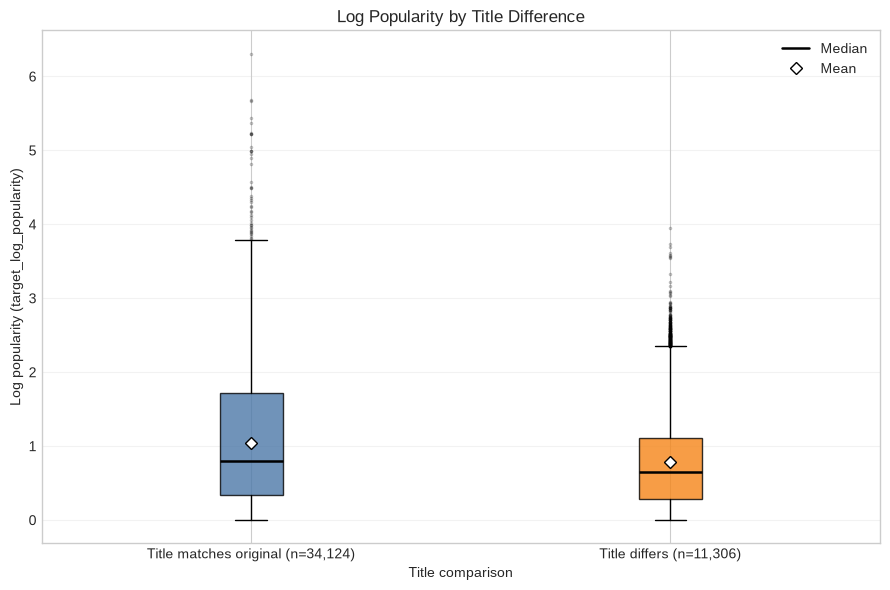

In [2]:
from matplotlib.lines import Line2D

plot_data = df[["title_differs_from_original", "target_log_popularity"]].dropna()
group_order = [0, 1]
groups = [
    plot_data.loc[plot_data["title_differs_from_original"] == value, "target_log_popularity"]
    for value in group_order
]
group_labels = [
    f"Title matches original (n={len(groups[0]):,})",
    f"Title differs (n={len(groups[1]):,})",
]

fig, ax = plt.subplots(figsize=(9, 6))
boxplot = ax.boxplot(
    groups,
    positions=[1, 2],
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6},
    medianprops={"color": "black", "linewidth": 1.8},
    flierprops={"marker": ".", "markersize": 3, "alpha": 0.25},
)
for box, color in zip(boxplot["boxes"], ["#4C78A8", "#F58518"]):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticks([1, 2], group_labels)
ax.set_title("Log Popularity by Title Difference")
ax.set_xlabel("Title comparison")
ax.set_ylabel("Log popularity (target_log_popularity)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    handles=[
        Line2D([0], [0], color="black", linewidth=1.8, label="Median"),
        Line2D([0], [0], marker="D", color="black", markerfacecolor="white", linestyle="None", label="Mean"),
    ],
    frameon=False,
)
fig.tight_layout()
plt.show()

**Insight:** The median log popularity is lower for movies with a different title (0.65) than for movies whose title matches the original (0.81). This is an unadjusted association, not evidence that changing a title causes lower popularity.

## Correlation Heatmap: Text Features and Popularity

Pearson correlations show the direction and strength of each pairwise linear association.

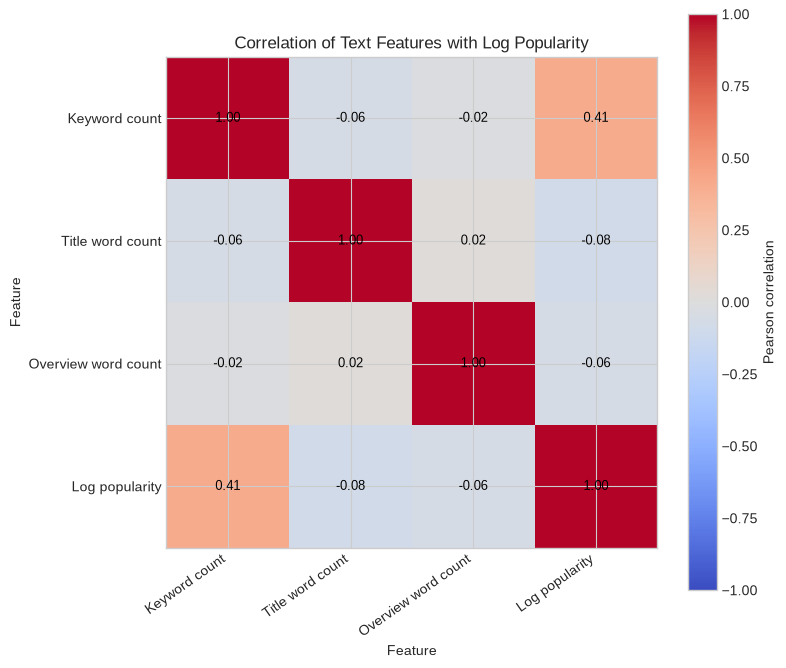

In [3]:
feature_columns = [
    "keyword_count",
    "title_word_count",
    "overview_word_count",
    "target_log_popularity",
]
feature_labels = [
    "Keyword count",
    "Title word count",
    "Overview word count",
    "Log popularity",
]
corr = df[feature_columns].corr()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="equal")
ax.set_xticks(np.arange(len(feature_labels)), feature_labels, rotation=35, ha="right")
ax.set_yticks(np.arange(len(feature_labels)), feature_labels)
for row in range(len(feature_labels)):
    for column in range(len(feature_labels)):
        value = corr.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.set_title("Correlation of Text Features with Log Popularity")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

**Insight:** Keyword count has the strongest correlation with log popularity among these text features (r = 0.41). Title and overview word counts have weak negative correlations; these relationships are descriptive, not causal.

In [4]:
display(df.head())
print()
display(df.info())

,id,target_log_popularity,release_year,release_month,release_decade,log_budget,log_revenue,runtime,genre_count,has_collection,...,director,top_cast,keywords,title,original_title,overview,original_language,status,budget_reported,revenue_reported
0,862,3.133185,1995.0,10.0,1990.0,17.216708,19.738573,81.0,3,1,...,John Lasseter,"[""Tom Hanks"", ""Tim Allen"", ""Don Rickles"", ""Jim...","['jealousy', 'toy', 'boy', 'friendship', 'frie...",Toy Story,Toy Story,"Led by Woody, Andy's toys live happily in his ...",en,Released,1,1
1,8844,2.891235,1995.0,12.0,1990.0,17.989898,19.386893,104.0,3,0,...,Joe Johnston,"[""Robin Williams"", ""Jonathan Hyde"", ""Kirsten D...","['board game', 'disappearance', ""based on chil...",Jumanji,Jumanji,When siblings Judy and Peter discover an encha...,en,Released,1,1
2,15602,2.542617,1995.0,12.0,1990.0,NaN,NaN,101.0,2,1,...,Howard Deutch,"[""Walter Matthau"", ""Jack Lemmon"", ""Ann-Margret...","['fishing', 'best friend', 'duringcreditssting...",Grumpier Old Men,Grumpier Old Men,A family wedding reignites the ancient feud be...,en,Released,0,0
3,31357,1.580935,1995.0,12.0,1990.0,16.588099,18.215526,127.0,3,0,...,Forest Whitaker,"[""Whitney Houston"", ""Angela Bassett"", ""Loretta...","['based on novel', 'interracial relationship',...",Waiting to Exhale,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",en,Released,1,1
4,11862,2.239381,1995.0,2.0,1990.0,NaN,18.153832,106.0,1,1,...,Charles Shyer,"[""Steve Martin"", ""Diane Keaton"", ""Martin Short...","['baby', 'midlife crisis', 'confidence', 'agin...",Father of the Bride Part II,Father of the Bride Part II,Just when George Banks has recovered from his ...,en,Released,0,1



<class 'pandas.DataFrame'>
RangeIndex: 45430 entries, 0 to 45429
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           45430 non-null  int64  
 1   target_log_popularity        45430 non-null  float64
 2   release_year                 45346 non-null  float64
 3   release_month                45346 non-null  float64
 4   release_decade               45346 non-null  float64
 5   log_budget                   8880 non-null   float64
 6   log_revenue                  7398 non-null   float64
 7   runtime                      43615 non-null  float64
 8   genre_count                  45430 non-null  int64  
 9   has_collection               45430 non-null  int64  
 10  company_count                45430 non-null  int64  
 11  country_count                45430 non-null  int64  
 12  spoken_language_count        45430 non-null  int64  
 13  cast_size                 

None

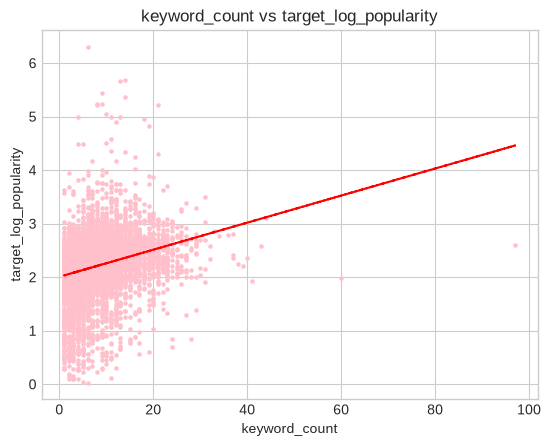

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

In [5]:
df1 = df.dropna()
y = df1['target_log_popularity']
x = df1['keyword_count']

z = np.polyfit(x, y, 1)
p = np.poly1d(z)

plt.scatter(x, y, s=5, color='pink', edgecolors='pink')
plt.plot(x, p(x), "r--")
plt.title("keyword_count vs target_log_popularity")
plt.xlabel("keyword_count")
plt.ylabel("target_log_popularity")
plt.show()

plt.figure(figsize=(10,5))

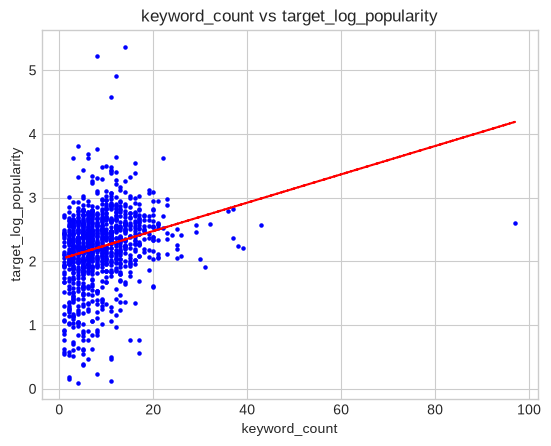

In [6]:
df_sample = df.sample(10000).dropna()

y = df_sample['target_log_popularity']
x1 = df_sample['keyword_count']


z = np.polyfit(x1, y, 1)
p = np.poly1d(z)

plt.scatter(x1, y, s=5, color='blue', edgecolors='blue')
plt.plot(x1, p(x1), "r--")
plt.title("keyword_count vs target_log_popularity")
plt.xlabel("keyword_count")
plt.ylabel("target_log_popularity")
plt.show()

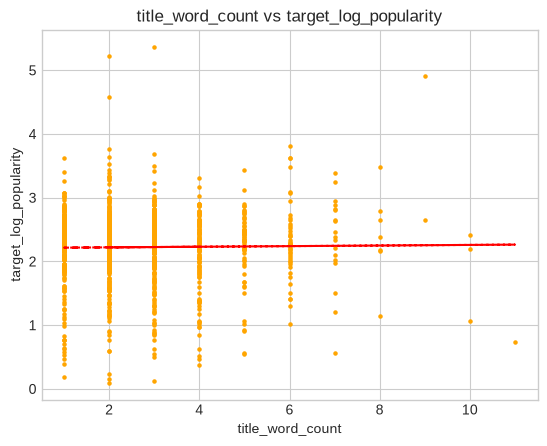

In [7]:
x2 = df_sample['title_word_count']
z = np.polyfit(x2, y, 1)
p = np.poly1d(z)
plt.scatter(x2, y, s=5, color='orange', edgecolors='orange')
plt.plot(x2, p(x2), "r--")
plt.title("title_word_count vs target_log_popularity")
plt.xlabel("title_word_count")
plt.ylabel("target_log_popularity")
plt.show()

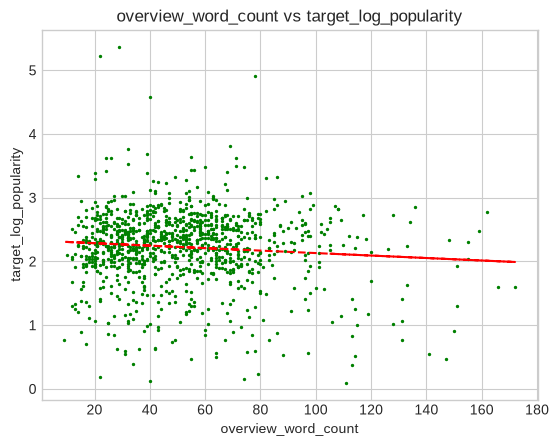

In [8]:
x3 = df_sample['overview_word_count']
z = np.polyfit(x3, y, 1)
p = np.poly1d(z)
plt.scatter(x3, y, s=2, color='green', edgecolors='green')
plt.plot(x3, p(x3), "r--")
plt.title("overview_word_count vs target_log_popularity")
plt.xlabel("overview_word_count")
plt.ylabel("target_log_popularity")
plt.show()

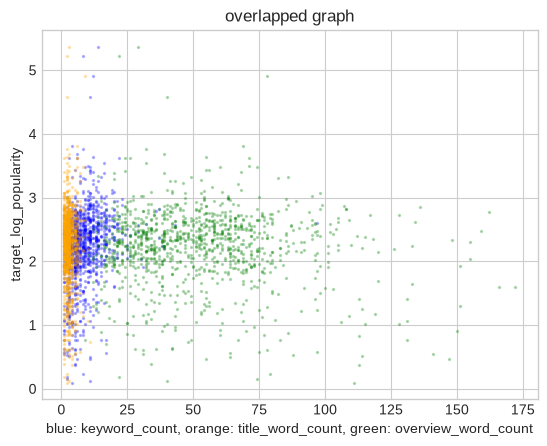

In [9]:
plt.scatter(x1, y, s=2, color='blue', edgecolors='blue', alpha=0.25)
plt.scatter(x2, y, s=2, color='orange', edgecolors='orange', alpha=0.25)
plt.scatter(x3, y, s=2, color='green', edgecolors='green', alpha=0.25)
plt.title("overlapped graph")
plt.xlabel("blue: keyword_count, orange: title_word_count, green: overview_word_count")
plt.ylabel("target_log_popularity")
plt.show()